In [8]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, Dense, Embedding, Flatten, Concatenate
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

In [9]:
from google.colab import drive
drive.mount('/content/drive',force_remount=True)

Mounted at /content/drive


In [10]:
symbols = ["AAPL","AIG", "BAC", "GS","MNST","MSFT","NKE","PFE","PLUG","SHOP","SPCE"]
path = "/content/drive/MyDrive/Βαση Δεδομενων/"

datasets = []

for symbol in symbols:
    df = pd.read_excel(f"{path}{symbol}_Data_Technical_Indicators_Combined.xlsx", parse_dates=[0])
    df.rename(columns={df.columns[0]: "Date"}, inplace=True)
    df.set_index("Date", inplace=True)
    df = df.sort_index()
    # Υπολογίζουμε το Volatility ΜΟΝΟ μέσα στα δεδομένα αυτής της μετοχής
    df["Volatility"] = df.iloc[:, 8].shift(-1)
    df["Symbol"] = symbol
    datasets.append(df)

# Κοινές ημερομηνίες για όλες τις μετοχές
common_dates = datasets[0].index
for df in datasets[1:]:
    common_dates = common_dates.intersection(df.index)

# Φιλτράρουμε όλα τα dataframes για τις κοινές ημερομηνίες
for i in range(len(datasets)):
    datasets[i] = datasets[i].loc[common_dates]

# Ενοποίηση όλων των datasets
dataset = pd.concat(datasets, axis=0)
dataset = dataset.dropna()

le = LabelEncoder()
dataset["Symbol_enc"] = le.fit_transform(dataset["Symbol"])
num_symbols = dataset["Symbol_enc"].nunique()

features_volatility = [1, 2, 3, 9, 10, 11, 5, 16]

X_volatility_num = dataset.iloc[:, features_volatility]
X_volatility_sym = dataset["Symbol_enc"]
y_volatility = dataset['Volatility']

dates = dataset.index

valid_idx = y_volatility.notna()
X_volatility_num = X_volatility_num.loc[valid_idx]
X_volatility_sym = X_volatility_sym.loc[valid_idx]
y_volatility = np.log1p(y_volatility.loc[valid_idx])

In [11]:
print(X_volatility_num)
print(X_volatility_sym)
print(y_volatility)

                 High        Low      Close  Real Upper Band  \
Date                                                           
2019-01-02  37.930661  36.827482  37.708591          43.4714   
2019-01-03  34.795449  33.907176  33.952545          42.8920   
2019-01-04  35.471204  34.336985  35.401955          42.4470   
2019-01-07  35.538069  34.838433  35.323162          42.0077   
2019-01-08  36.252032  35.464047  35.996532          41.7450   
...               ...        ...        ...              ...   
2024-12-23   6.220000   6.015000   6.120000           7.3798   
2024-12-24   6.220000   5.940000   6.210000           7.2129   
2024-12-26   6.670000   6.070000   6.500000           7.1512   
2024-12-27   6.770000   6.360000   6.380000           7.0739   
2024-12-30   6.240000   5.820000   5.980000           6.9129   

            Real Middle Band  Real Lower Band      RSI        VIX  
Date                                                               
2019-01-02           39.1471   

In [12]:
test_size = 0.2
total_len = len(common_dates)
test_len = int(total_len * test_size)

train_dates = common_dates[:-test_len]
test_dates  = common_dates[-test_len:]

X_num_train = X_volatility_num.loc[X_volatility_num.index.isin(train_dates)]
X_sym_train = X_volatility_sym.loc[X_volatility_sym.index.isin(train_dates)]
y_train = y_volatility.loc[y_volatility.index.isin(train_dates)]

X_num_test = X_volatility_num.loc[X_volatility_num.index.isin(test_dates)]
X_sym_test = X_volatility_sym.loc[X_volatility_sym.index.isin(test_dates)]
y_test = y_volatility.loc[y_volatility.index.isin(test_dates)]

val_size = 0.2
val_len = int(len(train_dates) * val_size)

train_dates_final = train_dates[:-val_len]
val_dates = train_dates[-val_len:]

X_num_train_final = X_volatility_num.loc[X_volatility_num.index.isin(train_dates_final)]
X_sym_train_final = X_volatility_sym.loc[X_volatility_sym.index.isin(train_dates_final)]
y_train_final = y_volatility.loc[y_volatility.index.isin(train_dates_final)]

X_num_val = X_volatility_num.loc[X_volatility_num.index.isin(val_dates)]
X_sym_val = X_volatility_sym.loc[X_volatility_sym.index.isin(val_dates)]
y_val = y_volatility.loc[y_volatility.index.isin(val_dates)]

In [13]:
test_df = pd.concat([X_num_test,X_sym_test.rename("Symbol"),y_test.rename("Target")],axis=1)

# Αποθήκευση στο Google Drive
save_path = "/content/drive/MyDrive/test_set_volatility_aligned.csv"
test_df.to_csv(save_path)

print(f"Test set αποθηκεύτηκε στο: {save_path}")

Test set αποθηκεύτηκε στο: /content/drive/MyDrive/test_set_volatility_aligned.csv


In [14]:
sc = StandardScaler()
X_num_train_final = sc.fit_transform(X_num_train_final)
X_num_val = sc.transform(X_num_val)
X_num_test = sc.transform(X_num_test)

In [15]:
num_input = Input(shape=(X_num_train_final.shape[1],), name="num_input")
sym_input = Input(shape=(1,), name="sym_input")

embed_dim = 2
sym_embed = Embedding(input_dim=num_symbols,output_dim=embed_dim,name="symbol_embedding")(sym_input)
sym_embed = Flatten()(sym_embed)
x = Concatenate()([num_input, sym_embed])
x = Dense(32, activation="relu")(x)
x = Dense(16, activation="relu")(x)
output = Dense(1, activation="linear")(x)
model = Model(inputs=[num_input, sym_input], outputs=output)
model.compile(optimizer = 'adam', loss = 'mse', metrics=[tf.keras.metrics.MeanAbsoluteError(name='mae'),tf.keras.metrics.RootMeanSquaredError(name='rmse'),tf.keras.metrics.MeanAbsolutePercentageError(name='mape')])
early_stopping = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
history=model.fit([X_num_train_final, X_sym_train_final],y_train_final,validation_data=([X_num_val, X_sym_val], y_val),batch_size = 16, epochs = 1000,callbacks=[early_stopping])

Epoch 1/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1549 - mae: 0.2591 - mape: 32.3536 - rmse: 0.3935 - val_loss: 0.0547 - val_mae: 0.1628 - val_mape: 13.2336 - val_rmse: 0.2340
Epoch 2/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0607 - mae: 0.1609 - mape: 21.5983 - rmse: 0.2463 - val_loss: 0.0409 - val_mae: 0.1556 - val_mape: 14.4428 - val_rmse: 0.2022
Epoch 3/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0478 - mae: 0.1449 - mape: 18.0935 - rmse: 0.2187 - val_loss: 0.0277 - val_mae: 0.1277 - val_mape: 11.9837 - val_rmse: 0.1663
Epoch 4/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0373 - mae: 0.1297 - mape: 15.6833 - rmse: 0.1931 - val_loss: 0.0306 - val_mae: 0.1307 - val_mape: 11.4257 - val_rmse: 0.1749
Epoch 5/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0286 - mae: 0.1168 - mape: 14.1249 - rmse: 0.1692 - val_loss: 0.0247 - val_mae: 0.1243 - val_mape: 12.1980 - val_rmse: 0.1571
Epoch 6/1000
665/665 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/s

In [16]:
test_loss, test_mae , test_rmse, test_mape = model.evaluate([X_num_test,X_sym_test], y_test)
print(f"Test Loss (MSE): {test_loss}, Test MAE: {test_mae}")

104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0311 - mae: 0.1198 - mape: 16.8384 - rmse: 0.1764
Test Loss (MSE): 0.031114362180233, Test MAE: 0.11984440684318542


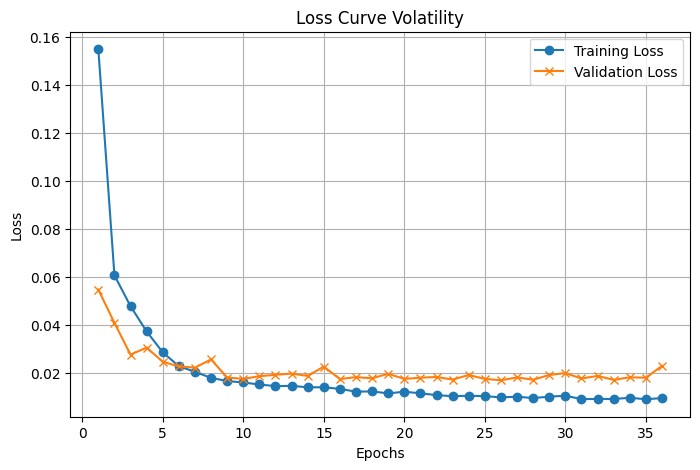

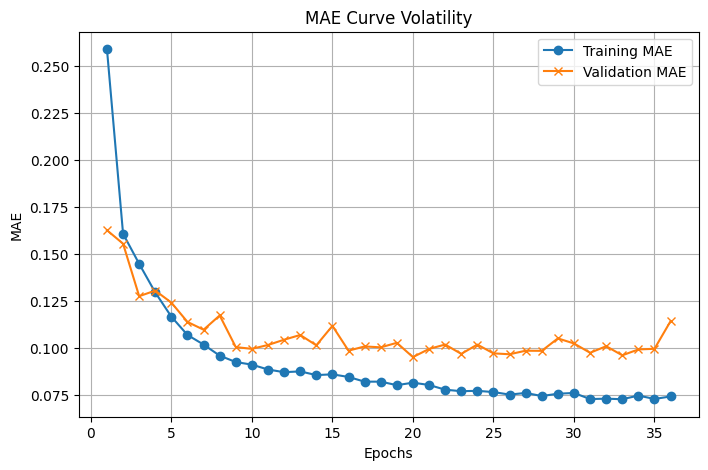

In [17]:
# Γραφικές παραστάσεις
epochs = range(1, len(history.history['loss']) + 1)

# Loss Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['loss'], label='Training Loss', marker='o')
plt.plot(epochs, history.history['val_loss'], label='Validation Loss', marker='x')
plt.title('Loss Curve Volatility')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

# MAE Curve
plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history['mae'], label='Training MAE', marker='o')
plt.plot(epochs, history.history['val_mae'], label='Validation MAE', marker='x')
plt.title('MAE Curve Volatility')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
y_pred = model.predict([X_num_test,X_sym_test])

y_test = y_test.to_numpy().reshape(-1, 1)

y_pred = np.expm1(y_pred)
y_test = np.expm1(y_test)

mae  = mean_absolute_error((y_test), (y_pred))
rmse = np.sqrt(mean_squared_error((y_test), (y_pred)))
mape = np.mean(np.abs(((y_test) - (y_pred)) / (y_test))) * 100
r2   = r2_score((y_test), (y_pred))
relative_mae= mae / np.mean(y_test) * 100

print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.3f}")
print(f"Relative MAE : {relative_mae:.2f}%")


104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE  : 0.48
RMSE : 0.76
MAPE : 26.85%
R²   : 0.931
Relative MAE : 17.16%
